# 8. Butadiene: Transition State for Rotation

We expect butadiene to prefer a **flat** *syn* or *anti* conformation. These **two** possible **conformations** are designated "*s-cis*" and "*s-trans*". The "s" refers to the &sigma; bond involved. There should be an energy maximum when the **torsion** angle is 90&deg; due to the loss of **conjugation** when the two &pi; bonds are orthogonal.

The **change** in electronic structure as the central bond rotates is similar to a chemical **reaction**. Molecular orbitals are being substantially changed and we proceed from one stable conformation **to another**. We could view the highest energy point in this potential energy profile for rotation as a **transition state** in the change from *s-cis* to *s-trans*. In this chapter, we will explore the **rotational potential energy profile** for butadiene and introduce the concept of **optimizing** a transition state structure.

We will **model** butadiene and determine its most stable **configuration** in the *s-trans* and *s-cis* rotational conformers. We will then estimate the energy **difference** between the two conformers and use this value to estimate the equilibrium constant between the two states. We will **scan** through a rotation of the central bond to locate the highest energy structure along the path. We will use the **energy barrier** to calculate an estimate for the rate of the process for rotating between the conformations and draw a **conclusion** as to whether there is a barrier to rotation.

Finally we will use an optimized **structure** that is near the energy **maximum** as a starting point for **optimizing** the structure of the **transition state** for the bond rotation.

### Settings

Run this cell first. It loads the book's helper module, `gamess_tools.py`, which finds *GAMESS* using the location you set in `gamess_settings.py` on the [setup page](1_Setup.ipynb). The `.log` files are written into the `runs/` folder next to this notebook. All the jobs on this page use the small 3-21G<sup>*</sup> basis set; the whole notebook runs in a few minutes.

In [1]:
# ===== SETTINGS =========================================================
# Your GAMESS location is set ONCE, in gamess_settings.py (next to this
# notebook). Edit that file, save it, and restart the kernel.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import gamess_tools as gt

INPUTS = Path("inputs")     # input files that come with the book
RUNS = Path("runs")         # where log files and new input files are written
RUNS.mkdir(exist_ok=True)

HARTREE_TO_KJMOL = 2625.5   # 1 hartree = 2625.5 kJ/mol
TORSION = 5                 # the C-C-C-C torsion is coordinate 6 in $ZMAT (index 5 in Python)
# ========================================================================

## Optimizing the *trans* Conformer

We will begin with a **review** of building molecules and optimizing structure. We will **build** both *cis* and *trans*-butadiene and attempt to **optimize** the structures. We will learn about some pitfalls along the way. Let us now **begin** with *trans*.

### Building *trans*-Butadiene

Run *MacMolPlt*. Click on `Builder` &rarr; `Show Build Tools`. Choose `carbon atoms` and set the `coordination number` to `3` (three bonds to an *sp<sup>2</sup>* carbon). Then click in the window to **build** the molecule. A carbon with three connections will appear. Then click on one of the **connections** to add a new carbon. When you have added all four carbon atoms, change the atom to hydrogen and then click on the remaining connections to include C-H bonds. **Trial and error** are your true teachers.

```{figure} images/Butadiene1.png
---
width: 450px
name: fig7_1A
---
*MacMolPlt* window with the initial structure for butadiene.
```

The above **initial structure** is a rough sketch. We will need to calculate the correct structure by creating an input file for *GAMESS*. Click on `Subwindow` &rarr; `Input Builder` and set the following parameters:

- In the `Control` section, set `Run Type` to `Optimization`. This will instruct *GAMESS* that we are doing a calculation to find the **optimized** molecular geometry.

- In the `Basis` section, set `Basis Set` to `3-21G` and set `#D and F heavy atom polarizations functions` to `1`. This means that we are running the calculation using the 3-21G<sup>*</sup> basis set. This is a low level of theory and is suitable for quick **calculations** that we want to be able to use and interpret during class.

- In the `Data` section, set `Coord. Type` to `Z-Matrix` and set `# of Z-matrix variables` to `24` (10 atoms so 3N – 6 = 24).

- In the `Misc. Prefs` section, check the `MolPlt` button. This will ensure that *GAMESS* outputs information in a **format** that can be read by the *MacMolPlt* application.

- Click on the `Edit and Save` button in the bottom of the `Input Builder` window. Then click on `Save As…` and save your file. Choose a name like `butadiene.inp`.

### Preparing to use *GAMESS*

Here in {numref}`inputfile1` is the input file generated by *MacMolPlt*…

```{literalinclude} inputs/butadiene.inp
:label: inputfile1
:caption: inputs/butadiene.inp
:linenos: True
```

### Optimizing the Structure

Now we will feed the **input file** into the *GAMESS* program. The job will run and produce an output file that will contain a description of the **structure** with the minimum calculated overall energy. This might be the most **stable** structure for our molecule.

In the original version of this book the job was submitted with *GamessQ*. Here `gt.run_gamess()` does it. This will produce an **output file** that is rich in information. Below, we will also pause for a detailed **discussion** of the contents of the output .log file.

In [2]:
trans_log = gt.run_gamess(INPUTS / "butadiene.inp")

butadiene: finished normally (butadiene.log)


### The Output File

An output file with the extension “.log” has been created in the `runs/` folder. This has all the **results** of the calculation. An entire file is presented in {numref}`fig7_1B` in very tiny print, with the sections that will be discussed next highlighted. The [input file](butadiene.inp.md) and the [output file](butadiene.log.md) from my original run are available in text format. Your file, `runs/butadiene.log`, will have the same sections, but the line numbers may differ a little.

```{figure} images/BUTADIENE_Rotation-ALL.png
:width: 500px
:label: fig7_1B
The *GAMESS* output file with annotations.
```

*Python* can find where each section starts in **your** log file. The cell below looks for a piece of text that marks the start of each section and prints its line number.

In [3]:
lines = trans_log.read_text().splitlines()
landmarks = [
    ("Input file (INPUT CARD>)",          "INPUT CARD>"),
    ("Setup: internal coordinates",       "INTERNAL COORDINATES"),
    ("Initial energy calculation",        "NSERCH=   0"),
    ("First optimization step",           "NSERCH=   1"),
    ("Final results",                     "EQUILIBRIUM GEOMETRY LOCATED"),
    ("End of the job",                    "TERMINATED NORMALLY"),
]
for label, text in landmarks:
    first = next(n for n, line in enumerate(lines, start=1) if text in line)
    print(f"line {first:5d}  {label}")
print(f"{len(lines)} lines in total")

line   281  Input file (INPUT CARD>)
line   565  Setup: internal coordinates
line   635  Initial energy calculation
line  1597  First optimization step
line  3113  Final results
line  3690  End of the job
3710 lines in total


#### System Information and *GAMESS* Header
The **first part** of the file is information about the **computer** running *GAMESS* and the standard *GAMESS* header with credits and references.

#### Input File
The next section is a **copy** of the **input file**. The “`INPUT CARD>`” at the start of each line is an artifact of the FORTRAN heritage of *GAMESS*. There was once a day when each line would have been read in via a stack of **paper punch cards**. Never fold, spindle or mutilate your input file.

#### Setup
This section chronicles the *GAMESS* program **setting up** your calculations. We see outputs of our structure in **Cartesian coordinates** and in **internal coordinates**. This is followed by a list of the basis set **parameters**. Then the electrons are described according to the instructions of the input file. Toward the end of the setup, we see the final statement of internal coordinates. This was set up by the `$ZMAT` group at the end of the input file.

The important item here is that the **sixth parameter** in that set of internal **coordinates** is the **dihedral angle** along the central C–C bond of butadiene. It will always be the sixth item because the 4,3,2,1 parameter (the angle involving atoms 4, 3, 2 and 1) is the **sixth** in the `$ZMAT` list. We will be **freezing** this sixth parameter when we get to exploring all possible angles for this dihedral. That is the purpose of the `$ZMAT` group. We **declare** the parameters in the *Z-matrix* and can then address them by their position in the list. If we did not declare the `$ZMAT` list then we would not know in advance where *GAMESS* chose to put that parameter in the list.

#### Initial Energy Calculation
Next *GAMESS* performs an **energy** calculation using our initial input structure. The output includes data for molecular orbitals as well. *GAMESS* will give the MO information for the **first and last** calculations in an optimization run.

This calculation provides the **energy** and the first derivative of the energy, the **gradient**. The gradient tells *GAMESS* which **direction** to change bond lengths and angles to follow a **downhill** slope in the energy function. We will keep following that slope to the **bottom**, hopefully.

#### The First Optimization Step
The *GAMESS* program takes the input structure and changes the **bond lengths and angles** according to the gradient. It takes baby steps so as not to overshoot a possible minimum-energy destination. After applying these small changes, *GAMESS* performs another energy and gradient **calculation**. You will see the new structure reported at the beginning of this calculation. If you **compare** the internal coordinates used in the initial energy calculation to the internal coordinates used in step 1 you will see the **changes** made.

We can follow one coordinate, the C=C bond between atoms 2 and 1, through the file. Every table of internal coordinates has a line for it that contains `1 STRETCH   2  1`. In the tables headed `(BOHR,RAD) (ANG,DEG)` the two numbers are the length in bohr and in ångström. In the tables headed `(ANG,DEG) (H/B,H/RAD)` they are the length in ångström and the gradient.

In [4]:
for line in gt.grep("1 STRETCH   2  1", trans_log)[:6]:
    print(line)

   1 STRETCH   2  1                     2.9101780       1.5400000
   1 STRETCH   2  1                     2.9101780       1.5400000
   1 STRETCH   2  1                     1.5400000       0.1627843
   1 STRETCH   2  1                     2.7249960       1.4420059
   1 STRETCH   2  1                     1.4420059       0.1149319
   1 STRETCH   2  1                     2.4065028       1.2734666


The C=C double bond between atoms 1 and 2 starts at 1.54 Å and has changed to 1.44 Å after the first step. Its gradient (the second number in the gradient tables) gets smaller as the bond gets closer to its best length.

#### More Optimization Steps
This process is **repeated again and again**. The energy and gradient are calculated and then that information is used to change the structure along the downward slope of the energy function. This new structure is the input for the next energy and gradient calculation. We will repeat this process until the molecule is **no longer changing**. When the changes proposed by *GAMESS* drop below a certain threshold value, the program will declare that a “stationary point” has been reached. This is the place where the **first derivative** of the energy function is **zero**. It is the bottom of a well or the peak of a hill. Since we have been following the gradient downwards, we will assume that we have reached a **minimum** in energy.

The energy is reported near the end of each optimization step. We will **extract** these values and plot the progress with each step below.

#### Final Results
At the end of all this we have the **final structure** expressed in both Cartesian and internal coordinates and the final energy value for that structure. We can take these coordinates and use them in a new experiment if we wished.

Below is the section of the log file from the last step that reports the **final atomic coordinates** and the energy. The energy is on the `NSERCH` line at the top. The set of Cartesian coordinates is **useful** as input for 3-dimensional molecular **visualization** programs like UCSF Chimera, VMD or Avogadro. The internal coordinates that list bond lengths and angles follow.

In [5]:
gt.excerpt(trans_log, "EQUILIBRIUM GEOMETRY LOCATED", before=3, after=46)

 3110   NSERCH:   8  E=     -154.0594565686  GRAD. MAX=  0.0000626  R.M.S.=  0.0000215
 3111  
 3112  
 3113        ***** EQUILIBRIUM GEOMETRY LOCATED *****
 3114   COORDINATES OF ALL ATOMS ARE (ANGS)
 3115     ATOM   CHARGE       X              Y              Z
 3116   ------------------------------------------------------------
 3117   C           6.0  -1.8315147099   0.0955268947   0.0000000000
 3118   C           6.0  -0.6104014945  -0.4068198729  -0.0000000000
 3119   C           6.0   0.6104014945   0.4068198729   0.0000000000
 3120   C           6.0   1.8315147099  -0.0955268947   0.0000000000
 3121   H           1.0  -2.0077155939   1.1554304299   0.0000000000
 3122   H           1.0  -2.7009344743  -0.5324515300  -0.0000000000
 3123   H           1.0  -0.4691968027  -1.4731766379  -0.0000000000
 3124   H           1.0   0.4691968027   1.4731766379   0.0000000000
 3125   H           1.0   2.0077155939  -1.1554304299   0.0000000000
 3126   H           1.0   2.7009344743   0.5324

**Examining** the internal coordinates reveals that the C=C bond lengths (2,1 and 4,3) are 1.32 Å and the C–C bond length (3,2) is 1.47 Å. The dihedral angle along the C–C bond (4,3,2,1) is 180&deg;. `gt.internal_coordinates()` reads the same table, so *Python* can pick out the numbers we need.

In [6]:
ic = gt.internal_coordinates(trans_log)
for kind, atoms, value in ic[:6]:
    unit = "Å" if kind == "STRETCH" else "°"
    print(f"{kind:8s} {'-'.join(map(str, atoms)):10s} {value:10.4f} {unit}")

STRETCH  2-1            1.3204 Å
STRETCH  3-2            1.4671 Å
BEND     3-2-1        123.9559 °
STRETCH  4-3            1.3204 Å
BEND     4-3-2        123.9559 °
TORSION  4-3-2-1      180.0000 °


From the above internal coordinates, I can create a **diagram** of the optimized structure. See {numref}`fig7_1C`.

```{figure} images/Butadiene5.png
---
width: 500px
name: fig7_1C
---
Final results from the output file (step 8).
```

Take note that the diagram in {numref}`fig7_1C` was **constructed** by examining the **text** of the log file. We don't have to use a graphical interface such as *MacMolPlt*. Often, using internal coordinates gives us **easy** access to structural details.

## Extracting Information with *Python*

In the original version of this book we used the *Unix* tools described in the [Unix](1A_Unix.ipynb) chapter to **manipulate** the text output files and extract important bits of information. Here we do the same with *Python*.

### Extracting Information

We will now **extract** just the lines that we want from the large log file. In a terminal, *grep* is a tool that reads a file line by line and returns the lines that contain a text string. `gt.grep()` does exactly the same thing. `gt.grep("NSERCH", trans_log)` returns the **text lines** that I observed contained both the calculated energy and the step number for each optimization step.

In [7]:
nserch_lines = gt.grep("NSERCH", trans_log)
for line in nserch_lines:
    print(line)

 BEGINNING GEOMETRY SEARCH POINT NSERCH=   0 ...
          NSERCH=  0     ENERGY=    -153.9541764
 NSERCH:   0  E=     -153.9541763815  GRAD. MAX=  0.1079504  R.M.S.=  0.0475879
 BEGINNING GEOMETRY SEARCH POINT NSERCH=   1 ...
          NSERCH=  1     ENERGY=    -154.0213487
 NSERCH:   1  E=     -154.0213487172  GRAD. MAX=  0.0820348  R.M.S.=  0.0360230
 BEGINNING GEOMETRY SEARCH POINT NSERCH=   2 ...
          NSERCH=  2     ENERGY=    -154.0529077
 NSERCH:   2  E=     -154.0529076654  GRAD. MAX=  0.0642832  R.M.S.=  0.0252608
 BEGINNING GEOMETRY SEARCH POINT NSERCH=   3 ...
          NSERCH=  3     ENERGY=    -154.0584666
 NSERCH:   3  E=     -154.0584666467  GRAD. MAX=  0.0258182  R.M.S.=  0.0087885
 BEGINNING GEOMETRY SEARCH POINT NSERCH=   4 ...
          NSERCH=  4     ENERGY=    -154.0593156
 NSERCH:   4  E=     -154.0593156091  GRAD. MAX=  0.0053906  R.M.S.=  0.0023023
 BEGINNING GEOMETRY SEARCH POINT NSERCH=   5 ...
          NSERCH=  5     ENERGY=    -154.0593410
 NSERCH:   5

You can see that this is **every line** in the file **that contains** the string “`NSERCH`”. I want just the lines that contain the energy and the gradient. So I will keep only the lines that also contain “`GRAD`”. In a terminal I would “pipe” the output of one *grep* into a second *grep*. In *Python* we filter the list.

In [8]:
energy_lines = [line for line in nserch_lines if "GRAD" in line]
for line in energy_lines:
    print(line)

 NSERCH:   0  E=     -153.9541763815  GRAD. MAX=  0.1079504  R.M.S.=  0.0475879
 NSERCH:   1  E=     -154.0213487172  GRAD. MAX=  0.0820348  R.M.S.=  0.0360230
 NSERCH:   2  E=     -154.0529076654  GRAD. MAX=  0.0642832  R.M.S.=  0.0252608
 NSERCH:   3  E=     -154.0584666467  GRAD. MAX=  0.0258182  R.M.S.=  0.0087885
 NSERCH:   4  E=     -154.0593156091  GRAD. MAX=  0.0053906  R.M.S.=  0.0023023
 NSERCH:   5  E=     -154.0593410317  GRAD. MAX=  0.0064435  R.M.S.=  0.0026388
 NSERCH:   6  E=     -154.0594560426  GRAD. MAX=  0.0003388  R.M.S.=  0.0001087
 NSERCH:   7  E=     -154.0594564093  GRAD. MAX=  0.0000859  R.M.S.=  0.0000460
 NSERCH:   8  E=     -154.0594565686  GRAD. MAX=  0.0000626  R.M.S.=  0.0000215


`gt.nserch_energies()` does both steps and turns each line into a pair of numbers: (step, energy). In {numref}`fig7_1D`, we see a plot of the **relative energies** in each step. The energy in the result table was in hartrees (*E*<sub>h</sub>), a unit common in computational chemistry. There are 2625.5 kJ/mol in a hartree.

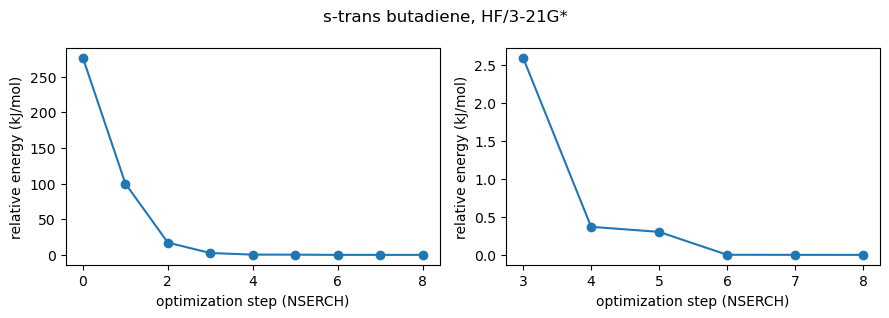

In [9]:
#| label: fig7_1D
#| caption: Relative energy as the optimization proceeds. The left plot shows all steps and the right plot shows the energy from step 3 to the end.
def plot_optimization(log_file, title, zoom_from=3):
    """Relative energy at each optimization step: all steps, and from step `zoom_from`."""
    steps, energies = np.array(gt.nserch_energies(log_file)).T
    relative = (energies - energies[-1]) * HARTREE_TO_KJMOL
    fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.2))
    left.plot(steps, relative, "o-")
    right.plot(steps[zoom_from:], relative[zoom_from:], "o-")
    for ax in (left, right):
        ax.set_xlabel("optimization step (NSERCH)")
        ax.set_ylabel("relative energy (kJ/mol)")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

plot_optimization(trans_log, "s-trans butadiene, HF/3-21G*")

The energy changes **quickly** in the first few steps and then we keep making **small changes** until the *GAMESS* program halted the optimization.

```{note}
You can learn more about *grep* online. Start at https://www-users.york.ac.uk/~mijp1/teaching/2nd_year_Comp_Lab/guides/grep_awk_sed.pdf and then keep going. When you are ready for the next level search the web for “regular expressions”. *Python* has them too, in the `re` module; `gamess_tools.py` uses one to read the `NSERCH` lines.
```

## Optimized Geometry of the *s-cis* Conformer

Butadiene can **rotate** around the central C–C bond. It can exist as a *s-cis* or a *s-trans* conformer. The energy barrier is small and the central bond can easily rotate. We could calculate the **optimized** structure for the *cis* conformer and compare that energy to the *trans* conformer.

### Changing The Input File

Let us rotate the central bond all the way around. The simplest way to do this is to **change** the 4,3,2,1 torsional angle from 180&deg; to 0&deg; in the **input file**. Here is the changed input file shown in {numref}`butadiene_122inp`.

```{literalinclude} inputs/butadiene_cis_flat.inp
:label: butadiene_122inp
:caption: inputs/butadiene_cis_flat.inp
:linenos: True
:emphasize-lines: 13
```

### Running The Job

In three seconds we are done and a new log file is created. In the original version of this book I opened the file in a **text editor**, scrolled down to the last iteration and **found** the resulting optimized structure and energy. `gt.excerpt()` prints the same part of the file: the last table of internal coordinates, which ends with the last `NSERCH` line.

In [10]:
cis_flat_log = gt.run_gamess(INPUTS / "butadiene_cis_flat.inp")
gt.excerpt(cis_flat_log, "NSERCH:", before=28, after=0)

butadiene_cis_flat: finished normally (butadiene_cis_flat.log)
 3084     3 BEND      3  2  1                126.6622009       0.0000182
 3085     4 STRETCH   4  3                     1.3200629      -0.0000151
 3086     5 BEND      4  3  2                126.6622009       0.0000181
 3087     6 TORSION   4  3  2  1               0.0000000       0.0000000
 3088     7 STRETCH   5  1                     1.0731576      -0.0000018
 3089     8 BEND      5  1  2                122.6579702      -0.0000182
 3090     9 TORSION   5  1  2  3               0.0000000      -0.0000000
 3091    10 STRETCH   6  1                     1.0727428       0.0000097
 3092    11 BEND      6  1  5                116.1262600       0.0000146
 3093    12 TORSION   6  1  5  2             180.0000000       0.0000000
 3094    13 STRETCH   7  2                     1.0749927       0.0000027
 3095    14 BEND      7  2  1                118.6116749      -0.0000113
 3096    15 TORSION   7  2  1  3             180.0000000     

We see the torsion `4,3,2,1` value is **zero** in the optimized structure. Is the **electronic demand** to maximize planarity and &pi;-orbital overlap able to completely trump the **steric cost** of pushing the end groups into close proximity? I don’t know about that. Look at the `3,2,1` bend. It represents the **angle** in the carbon chain. It is 126.7&deg;. This is much larger than the ideal 120&deg; angle. The bond angle is being **forced** open to minimize the steric clash of the atoms. But is this the lowest energy structure for the *s-cis* form of butadiene? {numref}`fig7_1E` shows a **diagram** for the result of this optimization.

```{figure} images/Butadiene7.png
---
width: 500px
name: fig7_1E
---
Result of optimization of flat *s-cis* conformer.
```

### Avoiding Traps and Pitfalls

The perfectly **flat** structure might be on a **maximum** energy point and unable to **snap out of it** because the gradients for the torsions are all calculated to be zero. Are we at a **peak** or in a valley?

### Breaking The Symmetry

Let’s simply **set** the torsions to 5&deg; away from flat and then let the calculation run. I will also set `NSTEP=100` in the `$STATPT` group of settings. The original value was `20`, and with the new starting structure the calculation would stop at 20 steps. If we stop on a count rather than when we find the stationary point we won’t be at the optimized **destination**. `NSTEP` should be set so that the calculation cannot take too long but I’m not worried about that here.

I’m going to do the same with the *s-trans* conformer as well. In that calculation we had set the `4,3,2,1` torsion to 180&deg; and it had remained there. We will **tweak** all the torsions by 5&deg; there as well.

Here in {numref}`butadiene_125` is the new input file for the *s-cis* conformer…

```{literalinclude} inputs/butadiene_cis.inp
:label: butadiene_125
:caption: inputs/butadiene_cis.inp
:linenos: True
:emphasize-lines: 8, 15
```

### The True *s-cis* Structure

Below is a text block from the result file.

In [11]:
cis_log = gt.run_gamess(INPUTS / "butadiene_cis.inp")
gt.excerpt(cis_log, "NSERCH:", before=28, after=0)

butadiene_cis: finished normally (butadiene_cis.log)
 7696     3 BEND      3  2  1                124.7972162      -0.0000215
 7697     4 STRETCH   4  3                     1.3193723       0.0000096
 7698     5 BEND      4  3  2                124.7942516      -0.0000160
 7699     6 TORSION   4  3  2  1              38.1506477      -0.0000155
 7700     7 STRETCH   5  1                     1.0734755      -0.0000001
 7701     8 BEND      5  1  2                121.8023269      -0.0000076
 7702     9 TORSION   5  1  2  3               1.9633861       0.0000243
 7703    10 STRETCH   6  1                     1.0729659      -0.0000018
 7704    11 BEND      6  1  5                116.6164065       0.0000031
 7705    12 TORSION   6  1  5  2            -179.1290216      -0.0000540
 7706    13 STRETCH   7  2                     1.0759226       0.0000009
 7707    14 BEND      7  2  1                119.4905849      -0.0000115
 7708    15 TORSION   7  2  1  3            -179.0128163      -0.000053

Once the **symmetry** of the flat structure was **broken**, the molecule had a whole other dimension to explore and it took 32 steps to reach a minimum energy. Most of the torsions are almost flat, as expected. However, the central C–C bond **settled** to a torsion angle of 38&deg;! That is very not flat. The *sp<sup>2</sup>* hybridization and the orbital overlap demand a flat structure, but the **realities** of steric clash push against that goal. We ended up being pushed out of planar as we maximized electron delocalization and minimized steric clash. It’s called **compromise** and it’s how the world gets along.

In a terminal, I used a *grep* pipe to **extract** the energy result for each step and then made a plot in a *Jupyter* notebook. Now the plotting function that we wrote above does it all in one line. See {numref}`fig7_1F`.

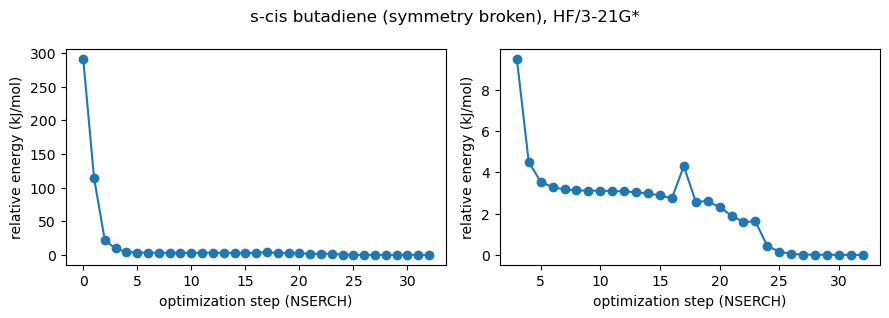

In [12]:
#| label: fig7_1F
#| caption: The energy path for minimization of the symmetry broken *s-cis* butadiene conformer. The left plot shows all steps and the right shows the energy from step 3 to the end.
plot_optimization(cis_log, "s-cis butadiene (symmetry broken), HF/3-21G*")

You can see in {numref}`fig7_1F` that the **path** to lowest energy was **not** as **smooth** when there are more options to explore. *GAMESS* took a **wrong turn** at least once. The changes applied according to the gradients were too large and we went **too far** along one of the energy gradients (there are 24 bond lengths, angles and torsions that are being adjusted) at various points. But *GAMESS* did find a **minimum** in the end. Is it the true minimum?

Try **tweaking** some of the torsions the other way. Set just some of the 5&deg; torsions to –5&deg; and some of the 175&deg; torsions to –175&deg;. Run the optimization **again** and see if you achieved the **same** structure and energy. How did it go? Where we start can influence where we end up. The program just **follows** a path **downwards**. It has no idea if it is heading to a divot or a canyon. It will happily **settle** into the bottom of either.

### Confirming the *s-trans* Structure

Below in {numref}`butadiene_transinp` is the input file for the tweaked *s-trans* conformer, followed by the final structure and energy from the optimization calculation.

```{literalinclude} inputs/butadiene_trans.inp
:label: butadiene_transinp
:caption: inputs/butadiene_trans.inp
:linenos: True
:emphasize-lines: 15
```

In [13]:
trans_tweak_log = gt.run_gamess(INPUTS / "butadiene_trans.inp")
gt.excerpt(trans_tweak_log, "NSERCH:", before=28, after=0)

butadiene_trans: finished normally (butadiene_trans.log)
 4594     3 BEND      3  2  1                123.9525002      -0.0000514
 4595     4 STRETCH   4  3                     1.3204695       0.0000813
 4596     5 BEND      4  3  2                123.9617693       0.0000241
 4597     6 TORSION   4  3  2  1             179.9466644      -0.0000212
 4598     7 STRETCH   5  1                     1.0744370       0.0000106
 4599     8 BEND      5  1  2                121.8217948       0.0000853
 4600     9 TORSION   5  1  2  3              -0.0223959      -0.0000141
 4601    10 STRETCH   6  1                     1.0724441      -0.0000029
 4602    11 BEND      6  1  5                116.3960004       0.0000053
 4603    12 TORSION   6  1  5  2             179.9556601      -0.0000390
 4604    13 STRETCH   7  2                     1.0756584       0.0000077
 4605    14 BEND      7  2  1                119.8969031      -0.0000488
 4606    15 TORSION   7  2  1  3             179.9878926      -0.00

The **torsion** angles were nearly identical to those when we began flat. Obviously the *s-trans* conformer **prefers** to be flat. The very slight perturbations from flat seen in the torsion angles can be attributed to a **snapshot** of a vibrating molecule (or, more honestly, to the optimization stopping as soon as the forces were small enough).

Let us **compare** the energies. There are 627.5 kcal/mol or 2625.5 kJ/mol in a hartree.

In [14]:
E = {name: gt.nserch_energies(log)[-1][1] for name, log in [
        ("flat s-trans", trans_log), ("tweaked s-trans", trans_tweak_log),
        ("flat s-cis", cis_flat_log), ("tweaked s-cis", cis_log)]}
for name, energy in E.items():
    print(f"{name:16s} {energy:.10f} hartree")

print(f"\ntweaked - flat s-trans: {(E['tweaked s-trans'] - E['flat s-trans']) * HARTREE_TO_KJMOL:8.4f} kJ/mol")
print(f"flat - tweaked s-cis:   {(E['flat s-cis'] - E['tweaked s-cis']) * HARTREE_TO_KJMOL:8.2f} kJ/mol")

flat s-trans     -154.0594565686 hartree
tweaked s-trans  -154.0594564864 hartree
flat s-cis       -154.0539432855 hartree
tweaked s-cis    -154.0551401544 hartree

tweaked - flat s-trans:   0.0002 kJ/mol
flat - tweaked s-cis:       3.14 kJ/mol


For the **tweaked** *s-trans* conformer input file and for the **optimized** flat structure from our very first calculation the energies differ by only 0.0002 kJ/mol: the same structure. The **energy** difference between the result of the flat *s-cis* input file and the result of the tweaked version (that escaped the “lock” of the perfectly symmetrical flat starting structure) was 3.14 kJ/mol. That is not a lot, but it is significant.

### How Much *s-cis* Is There?

The *s-trans* conformer is lower in energy than the twisted *s-cis* conformer. If we treat the electronic energy difference as the Gibbs energy difference (a rough approximation that ignores zero-point energy, vibrations and entropy) we can estimate the **equilibrium constant** at 298 K, $K = [s\text{-}cis]/[s\text{-}trans] = e^{-\Delta E/RT}$.

In [15]:
R = 8.314e-3          # kJ/(mol K)
T = 298.15            # K
dE_cis = (E["tweaked s-cis"] - E["flat s-trans"]) * HARTREE_TO_KJMOL
K = np.exp(-dE_cis / (R * T))
print(f"E(s-cis) - E(s-trans) = {dE_cis:.2f} kJ/mol")
print(f"K = {K:.4f}, so about {100 * K / (1 + K):.1f} % of the molecules are s-cis")

E(s-cis) - E(s-trans) = 11.33 kJ/mol
K = 0.0103, so about 1.0 % of the molecules are s-cis


Only about one molecule in a hundred is in the *s-cis* form at room temperature (twice that if we count both mirror-image twisted forms, at +38&deg; and –38&deg;). That matters for reactions such as the Diels-Alder reaction, which need the *s-cis* form.

## Freezing a Coordinate

We can **freeze** any coordinate in a calculation. This kind of calculation is not a true optimization as one length, angle or torsion (or even more than one if you wish) is being **held** at the initial value while the others are **allowed** to find the lowest energy possible. We could freeze the `4,3,2,1` torsion and allow all the others to **settle** to what is best.

In every coordinate list in our input files, the `4,3,2,1` torsion was the **sixth coordinate** in the list. This was established in the `$ZMAT` group that **lists** the coordinates in order in the `IZMAT(1)` matrix. This `IZMAT(1)` matrix was created by the *MacMolPlt* program that we used when we originally built the molecule. When you enter a value for the number of `ZMAT` variables in the `Input Builder` then *MacMolPlt* will create the `$ZMAT` group.

### The IZMAT(1) Matrix

The `IZMAT(1)` matrix in the **input file** presented below is a series of numbers separated by commas. The white space inserted by *MacMolPlt* is unnecessary but **helps** to group each coordinate for the reader.

The **first number** encountered is a “1”. This means that there will follow two atom numbers that define a *bond*. `1,2,1` defines a bond between atoms 2 and 1.

If the **next number** encountered is a “2”, then the program considers the next three values to be the atom numbers that define a **bond angle**. `2,3,2,1` defines the angle between atoms 3, 2 and 1. It is also the third element in the list shown and we see that the bond angle `3,2,1` is the third coordinate in the output file data.

When the number “3” is encountered at the **start** of a set then *GAMESS* looks to the following four values to define the atom numbers in a dihedral or bond **torsion angle**. `3,4,3,2,1` is the sixth set of values and defines the bond torsion for atoms 4, 3, 2 and 1. This is the central C–C bond torsion. It is the sixth set of values in the `ZMAT` list and is the sixth line in the list of `ZMAT` coordinates used in *GAMESS*. This **sixth coordinate** is the coordinate that we want to freeze.

*Python* can decode the list for us. The cell below reads the `IZMAT(1)` numbers from the input file and prints each coordinate in turn.

In [16]:
text = (INPUTS / "butadiene_cis_freeze.inp").read_text()
izmat = text.split("IZMAT(1)=")[1].split("$END")[0]
numbers = [int(n) for n in izmat.replace(",", " ").split()]

kinds = {1: ("bond", 2), 2: ("angle", 3), 3: ("torsion", 4)}
i, count = 0, 0
while i < len(numbers):
    kind, n_atoms = kinds[numbers[i]]
    count += 1
    atoms = numbers[i + 1:i + 1 + n_atoms]
    print(f"{count:2d}  {kind:8s} {','.join(map(str, atoms))}")
    i += 1 + n_atoms

 1  bond     2,1
 2  bond     3,2
 3  angle    3,2,1
 4  bond     4,3
 5  angle    4,3,2
 6  torsion  4,3,2,1
 7  bond     5,1
 8  angle    5,1,2
 9  torsion  5,1,2,3
10  bond     6,1
11  angle    6,1,5
12  torsion  6,1,5,2
13  bond     7,2
14  angle    7,2,1
15  torsion  7,2,1,3
16  bond     8,3
17  angle    8,3,4
18  torsion  8,3,4,2
19  bond     9,4
20  angle    9,4,3
21  torsion  9,4,3,7
22  bond     10,4
23  angle    10,4,9
24  torsion  10,4,9,3


```{literalinclude} inputs/butadiene_cis_freeze.inp
:label: butadiene_cisfreeze
:caption: inputs/butadiene_cis_freeze.inp
:linenos: True
:emphasize-lines: 9, 17
```

### The IFREEZ(1) Command

In the **input file** above, we see the command `IFREEZ(1)=6` in the `$STATPT` group. This will freeze the **sixth** `ZMAT` coordinate. We know that the C–C bond torsion is the sixth coordinate because of the `IZMAT(1)` matrix.

When we run the **optimization**, we get the following output. **Observe** that the **sixth** line for torsion `4,3,2,1` is **held** at zero degrees in the final structure.

In [17]:
cis_freeze_log = gt.run_gamess(INPUTS / "butadiene_cis_freeze.inp")
gt.excerpt(cis_freeze_log, "NSERCH:", before=28, after=0)

butadiene_cis_freeze: finished normally (butadiene_cis_freeze.log)
 4019     3 BEND      3  2  1                126.6599347       0.0000083
 4020     4 STRETCH   4  3                     1.3200608      -0.0000235
 4021     5 BEND      4  3  2                126.6583115      -0.0000082
 4022     6 TORSION   4  3  2  1               0.0000000       0.0000349
 4023     7 STRETCH   5  1                     1.0731616       0.0000036
 4024     8 BEND      5  1  2                122.6582022      -0.0000104
 4025     9 TORSION   5  1  2  3              -0.0368958      -0.0000233
 4026    10 STRETCH   6  1                     1.0727186      -0.0000083
 4027    11 BEND      6  1  5                116.1281550       0.0000239
 4028    12 TORSION   6  1  5  2             179.9872425       0.0000038
 4029    13 STRETCH   7  2                     1.0749908       0.0000011
 4030    14 BEND      7  2  1                118.6153555       0.0000086
 4031    15 TORSION   7  2  1  3            -179.9629289 

## The Potential Energy Surface for Rotation

We now have three energy points for the **rotation** of the central bond in butadiene. We found the best *s-cis* conformer where the central bond **torsion** was 38.15&deg;. We also found the best *s-trans* conformer where the **torsion angle** was 180&deg;. And we **locked** the torsion to 0&deg; and then found the best structure with that **constraint**. We now have the following potential energy **surface** for the rotation of the central bond. See {numref}`fig7_1_9`.

```{figure} images/Butadiene9.png
---
width: 350px
name: fig7_1_9
---
The hypothetical potential energy surface for bond rotation in butadiene.
```

### The Hypothesis

I have determined that there are **two stable conformers** (at least) at 38.15&deg; and 180&deg;. There will be a third conformer at –38.15&deg; due to symmetry. I have a proposed **energy barrier** of rotation between the two *s-cis* forms at 38.15&deg; and –38.15&deg; around the C–C bond in butadiene. The energy calculated when holding the torsion at 0&deg; is expected to be this barrier. The maximum electron stabilization occurs when &pi;-orbitals are parallel and it is at a minimum when &pi;-orbitals are at 90&deg;.

I therefore **hypothesize** that the energy barrier between the *s-cis* and *s-trans* forms will be at 90&deg;. Will the energy barrier be greater or less than the barrier due to steric strain at 0&deg;? It is time to perform an **experiment**.

### Experimental Design

I will perform the same geometry **optimization** calculations using a **frozen** torsion coordinate as before. I will choose 90&deg; for the angle and then run the calculation. I will **also** calculate torsion angles of 85&deg; and 95&deg; to ensure that I am at or near a maximum at 90&deg;.

All we need to do is to change the angle of the `4,3,2,1` torsion coordinate. It will be frozen by the `IFREEZ(1)=6` command. In the original version of this book I edited the input file by hand for every angle, submitted it through *GamessQ*, used *grep* to find the final energy and typed it into a list. Here we let *Python* do the repetitive part. Below is a **template** input file. It is the same as the frozen *s-cis* file, except that the torsion angle is the word `ANGLE`.

```{literalinclude} inputs/butadiene_scan_template.inp
:label: butadiene_90freeze
:caption: inputs/butadiene_scan_template.inp
:linenos: True
:emphasize-lines: 9, 17
```

The function `scan_point()` does the whole workflow for one angle: 1) **write** an input file with `ANGLE` replaced by a number (`gt.substitute()`, the *Python* version of `sed`); 2) **submit** the file to *GAMESS*; 3) **extract** the last energy value and the final torsion angle.

In [18]:
def scan_point(angle):
    """Optimize butadiene with the C-C-C-C torsion frozen at `angle` degrees.

    Returns (final torsion in degrees, final energy in hartree, log file)."""
    inp = gt.substitute(INPUTS / "butadiene_scan_template.inp",
                        RUNS / f"butadiene_scan_{angle:03d}.inp",
                        {"ANGLE": f"{angle:8.4f}"})
    log = gt.run_gamess(inp)
    torsion = gt.internal_coordinates(log)[TORSION][2]
    energy = gt.nserch_energies(log)[-1][1]
    return torsion, energy, log

scan = {}
for angle in (85, 90, 95):
    scan[angle] = scan_point(angle)

butadiene_scan_085: finished normally (butadiene_scan_085.log)


butadiene_scan_090: finished normally (butadiene_scan_090.log)


butadiene_scan_095: finished normally (butadiene_scan_095.log)


Here are the energies at each step of the 90&deg; job. This is what my *grep* pipe printed in the terminal, and the last line has the final energy.

In [19]:
for line in gt.grep("GRAD", scan[90][2]):
    if "NSERCH" in line:
        print(line)

 NSERCH:   0  E=     -153.9212555577  GRAD. MAX=  0.0934806  R.M.S.=  0.0476217
 NSERCH:   1  E=     -153.9931811281  GRAD. MAX=  0.0733539  R.M.S.=  0.0384399
 NSERCH:   2  E=     -154.0417447645  GRAD. MAX=  0.0377773  R.M.S.=  0.0155645
 NSERCH:   3  E=     -154.0471506996  GRAD. MAX=  0.0214345  R.M.S.=  0.0077481
 NSERCH:   4  E=     -154.0486834174  GRAD. MAX=  0.0179406  R.M.S.=  0.0053598
 NSERCH:   5  E=     -154.0495050750  GRAD. MAX=  0.0116389  R.M.S.=  0.0053540
 NSERCH:   6  E=     -154.0502344681  GRAD. MAX=  0.0108497  R.M.S.=  0.0044200
 NSERCH:   7  E=     -154.0507202078  GRAD. MAX=  0.0050984  R.M.S.=  0.0018709
 NSERCH:   8  E=     -154.0508528178  GRAD. MAX=  0.0024092  R.M.S.=  0.0010775
 NSERCH:   9  E=     -154.0508915803  GRAD. MAX=  0.0021036  R.M.S.=  0.0007313
 NSERCH:  10  E=     -154.0509243010  GRAD. MAX=  0.0009671  R.M.S.=  0.0003707
 NSERCH:  11  E=     -154.0509320677  GRAD. MAX=  0.0009822  R.M.S.=  0.0002350
 NSERCH:  12  E=     -154.0509335661  GR

That will give me a **set of data** for as many angles as I want to try. In {numref}`fig7_1_10`, the energies for 85&deg;, 90&deg; and 95&deg; are added to the **plot** for the potential energy surface. The energies are relative to the *s-trans* conformer.

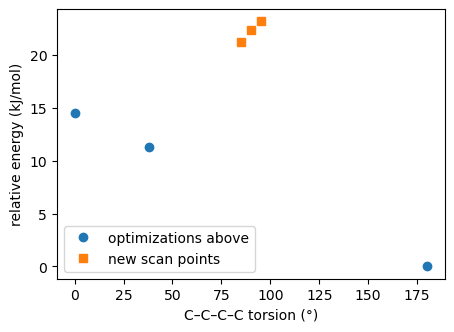

In [20]:
#| label: fig7_1_10
#| caption: The potential energy surface for bond rotation in butadiene.
E_ref = E["flat s-trans"]

def rel(energy):
    return (energy - E_ref) * HARTREE_TO_KJMOL

known = {0: E["flat s-cis"], 38.15: E["tweaked s-cis"], 180: E["flat s-trans"]}

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(list(known), [rel(e) for e in known.values()], "o", label="optimizations above")
ax.plot([t for t, e, _ in scan.values()], [rel(e) for t, e, _ in scan.values()], "s", label="new scan points")
ax.set_xlabel("C–C–C–C torsion (°)")
ax.set_ylabel("relative energy (kJ/mol)")
ax.legend()
plt.show()

Surprise! We are **not at a maximum**. The energy keeps going up from 85&deg; to 95&deg;. I will just keep changing the angle until we start coming back down. With a loop, it is no more work to do many more angles at once. The cell below scans from 0&deg; to 180&deg;; it takes a minute or two.

In [21]:
angles = [0, 5, 10, 20, 30, 35, 40, 45, 50, 60, 70, 80, 85, 90, 95,
          100, 105, 110, 120, 130, 140, 150, 160, 170, 175, 180]
for angle in angles:
    if angle not in scan:
        scan[angle] = scan_point(angle)

butadiene_scan_000: finished normally (butadiene_scan_000.log)


butadiene_scan_005: finished normally (butadiene_scan_005.log)


butadiene_scan_010: finished normally (butadiene_scan_010.log)


butadiene_scan_020: finished normally (butadiene_scan_020.log)


butadiene_scan_030: finished normally (butadiene_scan_030.log)


butadiene_scan_035: finished normally (butadiene_scan_035.log)


... (13 outputs left out)

butadiene_scan_160: finished normally (butadiene_scan_160.log)


butadiene_scan_170: finished normally (butadiene_scan_170.log)


butadiene_scan_175: finished normally (butadiene_scan_175.log)


butadiene_scan_180: finished normally (butadiene_scan_180.log)


Below is a table of the final energies and frozen torsion angles for each experiment that we performed, with the free *s-cis* optimization (38.15&deg;) added. The relative energies are measured from the lowest energy found.

In [22]:
profile = {t: e for t, e, _ in scan.values()}
profile[gt.internal_coordinates(cis_log)[TORSION][2]] = E["tweaked s-cis"]
profile = dict(sorted(profile.items()))
E_min = min(profile.values())

print(f"{'Angle':>8} {'Energy':>15} {'Rel. Energy':>12}")
print(f"{'(°)':>8} {'(hartree)':>15} {'(kJ/mol)':>12}")
for t, e in profile.items():
    print(f"{t:8.2f} {e:15.7f} {(e - E_min) * HARTREE_TO_KJMOL:12.2f}")

   Angle          Energy  Rel. Energy
     (°)       (hartree)     (kJ/mol)
    0.00    -154.0539433        14.48
    5.00    -154.0539922        14.35
   10.00    -154.0541309        13.98
   20.00    -154.0545762        12.81
   30.00    -154.0550029        11.69
   35.00    -154.0551184        11.39
   38.15    -154.0551402        11.33
   40.00    -154.0551325        11.35
   45.00    -154.0550308        11.62
   50.00    -154.0548095        12.20
   60.00    -154.0540449        14.21
   70.00    -154.0529871        16.99
   80.00    -154.0518630        19.94
   85.00    -154.0513572        21.26
   90.00    -154.0509343        22.38
   95.00    -154.0506281        23.18
  100.00    -154.0504707        23.59
  105.00    -154.0504893        23.54
  110.00    -154.0507019        22.99
  120.00    -154.0517055        20.35
  130.00    -154.0533040        16.15
  140.00    -154.0551449        11.32
  150.00    -154.0568825         6.76
  160.00    -154.0582690         3.12
  170.00    

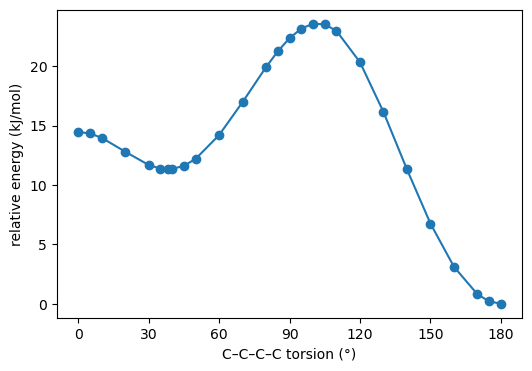

In [23]:
#| label: fig7_1_11
#| caption: The potential energy surface for bond rotation in butadiene.
fig, ax = plt.subplots(figsize=(6, 4))
t = np.array(list(profile))
e = (np.array(list(profile.values())) - E_min) * HARTREE_TO_KJMOL
ax.plot(t, e, "o-")
ax.set_xlabel("C–C–C–C torsion (°)")
ax.set_ylabel("relative energy (kJ/mol)")
ax.set_xticks(range(0, 181, 30))
plt.show()

The energy **peaks** somewhere between 100&deg; and 105&deg; and then starts to decrease. The values at each angle are very close, so I **estimate** the maximum energy is about midway between.

```{figure} images/Butadiene12.png
---
width: 500px
name: fig7_1_12
---
The structures corresponding to the maxima and minima in {numref}`fig7_1_11`.
```

Why is the maximum energy **found** at around 102&deg; rather than exactly 90&deg;? The **electronic** energy likely hits a maximum at 90&deg; and then starts to decrease as the angle rotates forward to 180&deg;. **Steric** repulsion from the other end of the molecule is still present and contributing to the total energy. It is decreasing as the angle opens up but results in an energy contribution that puts the maximum **nearer** to 100&deg; compared to 90&deg;. It seems that the steric interaction between the ends of the molecule pushed both stationary points to the right. The expected electronic minimum of 0&deg; was 38&deg; and the **expected** maximum of 90&deg; was >100&deg; when the steric effect is added in.

## Finding A Transition State

The **peak** of the energy barrier, between a C–C torsion of 100&deg; and 105&deg;, is the **transition state** for converting between the *s-trans* and *s-cis* conformers of butadiene. Can we find the **exact point** at which we reach maximum energy along the path of change?

The coordinate that we are changing is the torsion angle along the central C–C bond. We have **scanned** that coordinate between 0&deg; and 180&deg;. Scanning in this way is a good way to get **close** to a transition state. Each scan point is an optimized structure for that given **torsion value**. So all other coordinates have been minimized in energy (we hope) for each step in the scan. In theory, we are following the **lowest energy path** (a valley) uphill and down over a **saddle point** (a mountain pass). The saddle point is the transition state. There is one direction (coordinate) that takes you **up and then down** in energy as the saddle point is crossed. All other coordinates will only take you uphill (assuming that they are at minimum energy values after optimization).

```{figure} images/Butadiene13.png
---
width: 450px
name: fig7_1_13
---
An example of a saddle point in a potential energy surface for a reaction {cite:p}`saddle_point_svg`.
```

It is easy for *GAMESS* to find a **minimum**. It just follows every gradient downward. It is more challenging to find a **saddle point**, where one coordinate is maximized and all others are minimized. How do you find that balance point?

*GAMESS* has a **calculation** type called `RUNTYP=SADPOINT` that can do this. However, it needs to know what coordinate to follow to find the saddle point. The best way to do this is to construct a structure that is **close** to a hypothetical saddle point. The highest point of our scan seems like a good starting point.

### Finding The Imaginary Vibration

*GAMESS* still needs **lots of help**. First we need an **imaginary vibration** to follow. So we will have to perform a vibration calculation first. The imaginary vibration is often designated with a negative frequency. It is a vibration that moves along the **reaction coordinate**. All normal vibrations increase in energy as they move away from their centre points. The imaginary vibration is at a maximum at its centre. It is going downhill toward starting material or product as it **moves away** from the center.

A **structure** that is optimized (except for the frozen coordinate) and is very near the transition state structure should have an imaginary vibration. We need to perform a **vibration calculation** first.

In the original version of this book I opened the log file of the 100&deg; scan point in *MacMolPlt* and used `Subwindow` &rarr; `Input Builder` to create a new input file with `RunType` set to `Hessian`. Here *Python* writes the input file. It takes the final structure of the highest scan point and writes it as Cartesian coordinates (`COORD=UNIQUE`). The `$ZMAT` group is copied from the template, so the C–C torsion is still the sixth internal coordinate.

The `Hessian` run type calculates the information needed to determine the **vibrations** and their **frequencies**. These vibrations are the **vectors** along which the various coordinates are changed when we optimize. For **finding** the saddle point, we need to be **close** in structure and have a **vector** (the imaginary vibration) that **points** straight toward it. With higher levels of theory this can take a long time, but we are using a very low level of theory and won’t have to wait long. In many cases 3-21G<sup>*</sup> will not be suitable for an accurate **transition state** in a reaction but, since we are not making or breaking bonds, we should be OK. We also set up a vibrational analysis (`VIBANL=.TRUE.`) so that vibrations would be **calculated** out of the Hessian data and reported in the result file.

In [24]:
top_angle = max(scan, key=lambda a: scan[a][1])          # the highest-energy scan point
top_geom = gt.final_geometry(scan[top_angle][2])
zmat = (INPUTS / "butadiene_scan_template.inp").read_text().split(" $ZMAT")[1]
print(f"Highest scan point: {top_angle}°\n")

def butadiene_input(file_name, runtyp, extra_groups, atoms):
    """Write a C1 butadiene input with Cartesian atoms and the usual $ZMAT."""
    text = (
        f" $CONTRL SCFTYP=RHF RUNTYP={runtyp} MAXIT=30 MULT=1 COORD=UNIQUE NZVAR=24\n"
        "    MOLPLT=.TRUE. $END\n"
        " $SYSTEM TIMLIM=525600 MEMORY=1000000 $END\n"
        " $BASIS GBASIS=N21 NGAUSS=3 NDFUNC=1 $END\n"
        " $SCF DIRSCF=.TRUE. $END\n"
        f"{extra_groups}\n"
        " $DATA\n"
        f"butadiene, {runtyp} run\n"
        "C1\n"
        f"{gt.atom_lines(atoms)}\n"
        " $END\n"
        f" $ZMAT{zmat}")
    path = RUNS / file_name
    path.write_text(text)
    return path

hess_inp = butadiene_input("butadiene_Hess.inp", "HESSIAN",
                           " $FORCE METHOD=ANALYTIC VIBANL=.TRUE. $END", top_geom)
print(hess_inp.read_text())

Highest scan point: 100°

 $CONTRL SCFTYP=RHF RUNTYP=HESSIAN MAXIT=30 MULT=1 COORD=UNIQUE NZVAR=24
    MOLPLT=.TRUE. $END
 $SYSTEM TIMLIM=525600 MEMORY=1000000 $END
 $BASIS GBASIS=N21 NGAUSS=3 NDFUNC=1 $END
 $SCF DIRSCF=.TRUE. $END
 $FORCE METHOD=ANALYTIC VIBANL=.TRUE. $END
 $DATA
butadiene, HESSIAN run
C1
 C        6.0   -1.6947810072    0.3556940147   -0.0059070135
 C        6.0   -0.6694458282   -0.4389900605    0.2164066777
 C        6.0    0.6689345848   -0.2609668840   -0.4148035215
 C        6.0    1.6952658907    0.2974860987    0.1910445161
 H        1.0   -1.6212506697    1.2038893603   -0.6603746198
 H        1.0   -2.6468841214    0.1910757859    0.4616181802
 H        1.0   -0.7770883034   -1.2826907673    0.8761615046
 H        1.0    0.7756145478   -0.6331604171   -1.4191865188
 H        1.0    1.6225581533    0.6762581602    1.1932409953
 H        1.0    2.6473642549    0.4015916098   -0.2935828324
 $END
 $ZMAT IZMAT(1)=1,2,1, 1,3,2, 2,3,2,1, 1,4,3, 2,4,3,2, 3,4,3,2,1, 

In [25]:
hess_log = gt.run_gamess(hess_inp)
freqs = gt.frequencies(hess_log)
print("Frequencies (cm-1), imaginary ones negative:")
for i in range(0, len(freqs), 6):
    print("".join(f"{f:10.2f}" for f in freqs[i:i + 6]))

butadiene_Hess: finished normally (butadiene_Hess.log)
Frequencies (cm-1), imaginary ones negative:
   -165.07     10.25      0.20      0.05      0.13      5.45
      7.77    374.67    403.60    731.92    787.77    924.93
   1115.89   1122.69   1150.38   1152.55   1201.27   1265.39
   1461.64   1463.82   1587.89   1622.92   1828.39   1864.99
   3305.64   3306.36   3318.84   3323.20   3391.49   3391.83


When the job is finished, open `runs/butadiene_Hess.log` using *MacMolPlt*. Use `Subwindow` &rarr; `Frequencies` to **display the frequencies** calculated from the Hessian matrix. I observe a single **imaginary** frequency and I can click on the line in the Frequency window to see vectors displayed graphically in the main window. I observe that these vectors are as expected for bond rotation, so I think we have a **good starting point** for a saddle point optimization.

```{figure} images/Butadiene14.png
---
width: 500px
name: fig7_1_14
---
*MacMolPlt* display with frequencies and vectors.
```

In the log file, *GAMESS* writes an “I” after an imaginary frequency; `gt.frequencies()` turns it into a negative number. The first one is negative: that is our imaginary vibration. The next six are near zero; they are the three translations and three rotations of the whole molecule. Don’t trust the numbers too much but I am impressed that we are within the ball park. For example, the C–H stretch frequencies should be in the 3040-3100 cm<sup>–1</sup> range and the calculation finds them near 3350 cm<sup>–1</sup>. Not bad.

### Calculating The Saddle Point

Now that we know we have an acceptable **imaginary frequency** in our structure we can conduct a saddle point optimization calculation. The input file is written the same way, with `RUNTYP=SADPOINT`. `HESS=CALC` in the `$STATPT` group runs a **saddle point optimization** using a newly calculated Hessian matrix. I could have read in the previous Hessian result that we just calculated by using `HESS=READ` and copying the `$HESS` group from `runs/butadiene_Hess.dat`. This would be useful if that calculation had been expensive. Observe that I set the optimization tolerance to `OPTTOL=0.00001`. This is ten-fold **tighter** than for a typical optimization.

In [26]:
saddle_inp = butadiene_input("butadiene_saddle.inp", "SADPOINT",
                             " $STATPT OPTTOL=0.00001 NSTEP=20 HESS=CALC $END\n"
                             " $FORCE METHOD=ANALYTIC VIBANL=.TRUE. $END", top_geom)
saddle_log = gt.run_gamess(saddle_inp)
gt.excerpt(saddle_log, "NSERCH:", before=28, after=0)

butadiene_saddle: finished normally (butadiene_saddle.log)
 2383     3 BEND      3  2  1                123.7469387      -0.0000010
 2384     4 STRETCH   4  3                     1.3162097       0.0000003
 2385     5 BEND      4  3  2                123.7468844      -0.0000012
 2386     6 TORSION   4  3  2  1             102.0230006      -0.0000026
 2387     7 STRETCH   5  1                     1.0738933      -0.0000002
 2388     8 BEND      5  1  2                121.7739165      -0.0000000
 2389     9 TORSION   5  1  2  3              -0.5135888       0.0000003
 2390    10 STRETCH   6  1                     1.0733744      -0.0000005
 2391    11 BEND      6  1  5                116.5615599       0.0000004
 2392    12 TORSION   6  1  5  2             179.7772461      -0.0000006
 2393    13 STRETCH   7  2                     1.0763451       0.0000004
 2394    14 BEND      7  2  1                119.9221240       0.0000005
 2395    15 TORSION   7  2  1  3            -179.4909219       0.

In [27]:
ts_torsion = gt.internal_coordinates(saddle_log)[TORSION][2]
ts_energy = gt.nserch_energies(saddle_log)[-1][1]
print(f"Transition state: torsion {ts_torsion:.2f}°, energy {ts_energy:.10f} hartree, "
      f"{(ts_energy - E_min) * HARTREE_TO_KJMOL:.2f} kJ/mol above s-trans")

Transition state: torsion 102.02°, energy -154.0504557508 hartree, 23.63 kJ/mol above s-trans


The *GAMESS* calculation has determined that a **saddle point** exists when the C–C torsion angle is 102.02&deg;. I can now add that data point into my potential energy surface.

I had hypothesized that the transition state for bond rotation would occur between 100&deg; and 105&deg; and a little closer to 100&deg; than 105&deg;. I chose 102&deg; to make the diagram in {numref}`fig7_1_12`. *GAMESS* proposes that the transition state occurs at 102.02&deg;. Great minds think alike.

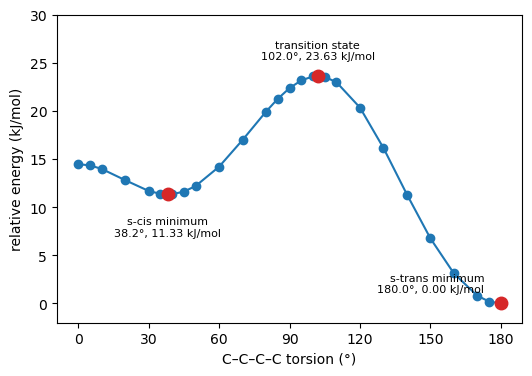

In [28]:
#| label: fig7_1_15
#| caption: The complete rotational potential energy profile for butadiene, with the stationary points (maxima and minima) in red.
profile[ts_torsion] = ts_energy
profile = dict(sorted(profile.items()))
t = np.array(list(profile))
e = (np.array(list(profile.values())) - E_min) * HARTREE_TO_KJMOL

stationary = {"s-cis minimum": gt.internal_coordinates(cis_log)[TORSION][2],
              "transition state": ts_torsion, "s-trans minimum": 180.0}

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(t, e, "o-", color="tab:blue", zorder=1)
for label, angle in stationary.items():
    y = (profile[angle] - E_min) * HARTREE_TO_KJMOL
    ax.plot(angle, y, "o", color="tab:red", ms=9, zorder=2)
    offset, align = {"s-cis minimum": ((0, -30), "center"),
                     "s-trans minimum": ((-12, 8), "right")}.get(label, ((0, 12), "center"))
    ax.annotate(f"{label}\n{angle:.1f}°, {y:.2f} kJ/mol", (angle, y),
                textcoords="offset points", xytext=offset, ha=align, fontsize=8)
ax.set_xlabel("C–C–C–C torsion (°)")
ax.set_ylabel("relative energy (kJ/mol)")
ax.set_xticks(range(0, 181, 30))
ax.set_ylim(-2, 30)
plt.show()

### How Fast Is the Rotation?

The barrier from *s-trans* to the transition state is about 24 kJ/mol. The Eyring equation, $k = \frac{k_\mathrm{B}T}{h} e^{-\Delta E^\ddagger/RT}$, turns a barrier into a rate constant. As before we use the electronic energy in place of the Gibbs energy of activation, so this is only a rough estimate.

In [29]:
kB_over_h = 2.0837e10          # Boltzmann constant / Planck constant, in 1/(s K)
for name, start in [("s-trans -> s-cis", E["flat s-trans"]), ("s-cis -> s-trans", E["tweaked s-cis"])]:
    barrier = (ts_energy - start) * HARTREE_TO_KJMOL
    k = kB_over_h * T * np.exp(-barrier / (R * T))
    print(f"{name}: barrier {barrier:5.2f} kJ/mol, k = {k:.1e} per second")

s-trans -> s-cis: barrier 23.63 kJ/mol, k = 4.5e+08 per second
s-cis -> s-trans: barrier 12.30 kJ/mol, k = 4.3e+10 per second


Is there a barrier to rotation? Yes, but a small one. Rotation about the central bond happens hundreds of millions of times a second at room temperature, so we could never isolate *s-cis* and *s-trans* butadiene as separate compounds. They are conformers, not isomers.

## Summary

These are the operations that we have performed over the course of this activity.

1.	**Build and Optimize** symmetrical butadiene. We calculated the optimized geometry of butadiene using an initial structure that was perfectly flat for the *s-cis* conformer and the *s-trans* conformer. The calculation easily found the bond lengths and angles for minimum energy but was trapped in stationary points for the torsion coordinates due to the flat symmetry.
2.	**Optimize** the asymmetrical structures of butadiene. We then started from a slightly randomized structure and found that the minimum for the *s-cis* conformer actually occurred when the C–C torsion was 38&deg;. We also saw that the *s-trans* conformer did indeed find an almost flat optimized structure.
3.	Scan the torsion angle to create an **energy profile**. We then performed a series of optimization calculations with the torsion coordinate for the &sigma; C–C bond frozen over a set of angles, using a *Python* loop and a template input file. This allowed us to observe that the transition state for rotation between *cis* and *trans* conformers was near a torsion angle of 102&deg;.
4.	Evaluate the **vibrations** near the transition state. We used a structure from the torsion scan to calculate the vibrations in a structure that was close to the hypothesized transition state. This was to confirm that there was an imaginary vibration that would likely take us toward the true transition state.
5.	Calculate an optimized **structure** for the **transition state**. After confirming that we had a good imaginary vibration, we performed a saddle point calculation that optimized the structure for the nearest transition state. We were very close already and found it easily. The T.S. was at a torsion angle of 102.0&deg;.

## Challenges

Here are some activities that you can perform to **increase** your understanding of using *GAMESS* to calculate potential energy profiles and transition states for bond rotations.

Calculate the **rotational** energy profile for **ethane** and for the C-C bond of propane. Compare the energy barriers between them and also with the butadiene and butane calculations. How does a steric energy barrier in ethane compare to that of butane? How does the electronic **cost** of **breaking** the conjugation in butadiene compare to breaking the C=C bond in ethylene?

Calculate the energy profile for **rotating** ethylene across the C=C double bond. What is the energy cost of effectively breaking a &pi;-bond during a bond rotation? **Compare** that to the cost of breaking the conjugation in butadiene.

The `scan_point()` function and the template file above can be reused for these challenges: make a template for your molecule with `ANGLE` in place of the torsion, and check which `$ZMAT` coordinate to freeze.

## AI Statement

This page was converted from the original Markdown page `7_Butadiene.md` to a *Jupyter* notebook with the help of Claude (Anthropic), following the author's instructions.

- **Original text kept (about 75 %).** The introduction, the building instructions, the tour of the output file, the discussion of flat and symmetry-broken conformers, the `IZMAT`/`IFREEZ` explanation, the hypothesis and experimental design, the transition-state discussion, the summary, the challenges and the *MacMolPlt*/diagram figures are the author's. All input files are the author's; the scan template is the author's 90&deg; file with the angle replaced by `ANGLE`. Small edits: typos fixed and figure captions tidied.
- **Written by AI.** The settings cell, all code cells and the sentences that introduce them; the landmark finder for the log file; the `IZMAT` decoder; the `scan_point()` loop; writing the Hessian and saddle-point inputs in *Python*; the plots, which replace the author's plot images; and the two short sections that estimate the equilibrium constant and the rotation rate (the original introduction promised these but the page did not include them).
- **Changed workflow.** Jobs are run with `run_gamess()` instead of *GamessQ*, and `grep`/pipes are replaced by `gt.grep()`, list filtering and `gt.nserch_energies()`. The section line numbers of the log file are now found by *Python*. The Hessian and saddle-point jobs start from the highest point of your own scan and keep the original Z-matrix numbering, so the torsion stays the sixth coordinate (the original used a second build with different atom numbering). The scan uses one set of starting torsions, so the energy at 180&deg; is the same as the *s-trans* optimization (the original table used a different build at 180&deg;).